# Modelo v1 – Línea base: regresión logística (modelos A y B)

**Proyecto:** Cumplimiento crediticio de los hogares colombianos (ELCO 2022) · **Versión:** v1

## 1. Configuración

In [49]:
#%pip install matplotlib scikit-learn pandas numpy cloudpickle mlflow==3.17.1

In [50]:
import os, hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mlflow, mlflow.sklearn
from mlflow.models import infer_signature

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, balanced_accuracy_score, f1_score, precision_score,
                             recall_score, roc_auc_score, PrecisionRecallDisplay, ConfusionMatrixDisplay)
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

VERSION = "v1"
SEED = 42    
DROP_DUPLICATES = False 
TARGET, GROUP = "objetivo_atraso", "DIRECTORIO"

EN_DATABRICKS = "DATABRICKS_RUNTIME_VERSION" in os.environ

if EN_DATABRICKS:
    DATA_PATH = "/Volumes/workspace/default/proyecto_elco_modelo1/ELCO_2022_creditos_ahorro_laboral_consolidado.csv"
    EXPERIMENT = "/elco-estado-de-pago-RaulM"
else:
    DATA_PATH = r"C:\Users\Raul M\Desktop\MAESTRIA\CICLOS\CICLO 6\DESPLIEGUE_SOLUCIONES\Proyecto\Entrega2\ELCO_2022_creditos_ahorro_laboral_consolidado.csv"
    EXPERIMENT = "elco-estado-de-pago"
    mlflow.set_tracking_uri("http://32.200.160.222:8050")

mlflow.set_experiment(EXPERIMENT)
print("Entorno:", "Databricks" if EN_DATABRICKS else "local",
      "| MLflow:", mlflow.get_tracking_uri(), "| experimento:", EXPERIMENT)

Entorno: local | MLflow: http://32.200.160.222:8050 | experimento: elco-estado-de-pago


In [51]:
from pathlib import Path
print(Path(DATA_PATH).exists())

True


## 2. Carga y variables derivadas

In [52]:
raw = pd.read_csv(DATA_PATH, encoding="utf-8-sig")
df = raw.drop_duplicates().reset_index(drop=True) if DROP_DUPLICATES else raw.copy()
assert df[GROUP].nunique() == 3020 and (df[TARGET] == (df["P2110"] == 2).astype(int)).all()

df.loc[df["P2107S1"] == 9999, "P2107S1"] = np.nan
df["antiguedad_anios"] = (2022.5 - (df["P2099S2"] + (df["P2099S1"] - 0.5) / 12)).clip(lower=0)
df["cuota_faltante"] = df["P2105S1"].isna().astype(float)
df["plazo_sin_definir"] = df["P2107S1"].isna().astype(float)
df["titular_no_reside"] = (df["P2109"] == 2).astype(float)
for c in ["P2104", "P2105S1", "P2107S1"]:
    df[c] = df[c].astype("float64")

print(f"Créditos: {len(df):,} | hogares: {df[GROUP].nunique():,} | con retrasos: {df[TARGET].sum()} ({df[TARGET].mean():.1%})")

Créditos: 4,013 | hogares: 3,020 | con retrasos: 675 (16.8%)


## 3. Selección de variables

**Modelo A**: solo variables del crédito. **Modelo B**: A + indicadores del hogar. La diferencia B − A mide el aporte de la información del hogar.

In [53]:
CRED_CAT = ["P2097", "P2098", "P2106"]
CRED_MONEY = ["P2104", "P2105S1"]
CRED_NUM = ["P2107S1", "antiguedad_anios"]
CRED_FLAG = ["cuota_faltante", "plazo_sin_definir", "titular_no_reside"]
HOGAR_NUM = ["n_personas_ahorro", "n_personas_con_ingresos", "n_personas_que_ahorran",
              "prop_que_ahorran_sobre_con_ingresos", "n_personas_con_cuenta",
              "n_personas_laboral", "n_personas_trabajo_semana"]
FEATURES = {"A": CRED_CAT + CRED_MONEY + CRED_NUM + CRED_FLAG,
            "B": CRED_CAT + CRED_MONEY + CRED_NUM + CRED_FLAG + HOGAR_NUM}
assert not {"P2110", "P2108", "saldo_sobre_valor", "P2107S2", "P2109S1", GROUP} & set(FEATURES["B"])
print({k: len(v) for k, v in FEATURES.items()}, "variables (A, B)")

{'A': 10, 'B': 17} variables (A, B)


## 4. Partición por hogar: entrenamiento 70 % / validación 15 % / prueba 15 %

In [54]:
gss = GroupShuffleSplit(n_splits=1, test_size=.30, random_state=SEED)
ix_tr, ix_tmp = next(gss.split(df, df[TARGET], groups=df[GROUP]))
train, temp = df.iloc[ix_tr].copy(), df.iloc[ix_tmp].copy()
gss2 = GroupShuffleSplit(n_splits=1, test_size=.50, random_state=SEED + 1)
ix_val, ix_te = next(gss2.split(temp, temp[TARGET], groups=temp[GROUP]))
val, test = temp.iloc[ix_val].copy(), temp.iloc[ix_te].copy()
for a, b in [(train, val), (train, test), (val, test)]:
    assert set(a[GROUP]).isdisjoint(set(b[GROUP])), "hay hogares repetidos entre conjuntos"

pd.DataFrame({"créditos": [len(x) for x in (train, val, test)],
              "hogares": [x[GROUP].nunique() for x in (train, val, test)],
              "% con retrasos": [x[TARGET].mean() * 100 for x in (train, val, test)]},
             index=["entrenamiento", "validación", "prueba"]).round(1)

,créditos,hogares,% con retrasos
entrenamiento,2808,2114,17.3
validación,613,453,15.3
prueba,592,453,16.0


## 5. Pipeline del modelo

El preprocesamiento va **dentro** del pipeline, de modo que el mismo artefacto se entrena, se versiona en MLflow y luego se sirve desde la API.
- Categóricas → *one-hot* (categorías con menos de 20 créditos se agrupan; las nuevas se ignoran).
- Montos → `log(1+x)`, mediana para faltantes y estandarización. Numéricas → mediana y estandarización.
- Variables del hogar → igual, más un indicador cuando la proporción de ahorro no está definida.
- **Regresión logística** con `class_weight="balanced"` (solo ~17 % de los créditos están en atraso).

In [55]:
HP = {"C": 1.0, "max_iter": 2000, "class_weight": None}
HP_TAG = "_".join(f"{k}-{v}" for k, v in HP.items())

def build_pipeline(fs):
    def numeric(log=False, indicator=False):
        steps = []
        if log:
            steps.append(("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")))
        steps += [("impute", SimpleImputer(strategy="median", add_indicator=indicator)), ("scale", StandardScaler())]
        return Pipeline(steps)
    parts = [("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20, sparse_output=False), CRED_CAT),
             ("money", numeric(log=True), CRED_MONEY), ("num", numeric(), CRED_NUM),
             ("flag", "passthrough", CRED_FLAG)]
    if fs == "B":
        parts.append(("hogar", numeric(indicator=True), HOGAR_NUM))
    prep = ColumnTransformer(parts, remainder="drop", verbose_feature_names_out=False)
    return Pipeline([("prep", prep), ("clf", LogisticRegression(random_state=SEED, **HP))])
build_pipeline("B")

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('money', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__

## 6. Evaluación y registro en MLflow

**Métricas** (clase "con retrasos"): PR-AUC (principal, no depende del umbral), recall, precisión y F1; además ROC-AUC y exactitud balanceada.

In [56]:
UMBRALES = np.round(np.arange(.10, .91, .05), 2)

def compute_metrics(y, proba, thr=0.5, prefix=""):
    y, pred = np.asarray(y), (np.asarray(proba) >= thr).astype(int)
    return {f"{prefix}recall": recall_score(y, pred), f"{prefix}precision": precision_score(y, pred, zero_division=0),
            f"{prefix}f1": f1_score(y, pred), f"{prefix}pr_auc": average_precision_score(y, proba),
            f"{prefix}roc_auc": roc_auc_score(y, proba), f"{prefix}balanced_accuracy": balanced_accuracy_score(y, pred)}

def best_threshold(y, proba):
    return float(UMBRALES[int(np.argmax([f1_score(y, (proba >= u).astype(int), zero_division=0) for u in UMBRALES]))])

def log_sklearn_model(pipe, X_ex, proba_ex):
    kw = dict(signature=infer_signature(X_ex, proba_ex), input_example=X_ex.head(3),
              serialization_format="cloudpickle")
    try:
        mlflow.sklearn.log_model(pipe, name="model", **kw)
    except TypeError:
        mlflow.sklearn.log_model(pipe, artifact_path="model", **kw)

def run_candidate(fs):
    cols = FEATURES[fs]
    pipe = build_pipeline(fs).fit(train[cols], train[TARGET])
    p_val, p_test = pipe.predict_proba(val[cols])[:, 1], pipe.predict_proba(test[cols])[:, 1]
    thr = best_threshold(val[TARGET], p_val)                       # solo con validación
    m_val, m_test = compute_metrics(val[TARGET], p_val, thr, "val_"), compute_metrics(test[TARGET], p_test, thr, "test_")

    with mlflow.start_run(run_name=f"{VERSION}_modelo{fs}_{HP_TAG}", nested=True):
        mlflow.set_tags({"version": VERSION, "feature_set": fs, "algoritmo": "LogisticRegression"})
        mlflow.log_params({"feature_set": fs, "n_variables": len(cols), "umbral": thr,
                           **{f"hp_{k}": v for k, v in HP.items()}})
        mlflow.log_dict({"features": cols}, "features.json")
        mlflow.log_metrics({**m_val, **m_test})

        fig, ax = plt.subplots(1, 2, figsize=(10, 4))
        PrecisionRecallDisplay.from_predictions(test[TARGET], p_test, ax=ax[0], name=f"Modelo {fs}")
        ax[0].set_title("Curva precisión-recall (prueba)")
        ConfusionMatrixDisplay.from_predictions(test[TARGET], (p_test >= thr).astype(int), ax=ax[1],
                                                display_labels=["Al día", "Con retrasos"], colorbar=False)
        ax[1].set_title(f"Matriz de confusión (umbral = {thr:.2f})")
        fig.tight_layout(); mlflow.log_figure(fig, "evaluacion.png"); plt.close(fig)

        coef = pd.DataFrame({"variable": pipe[:-1].get_feature_names_out(), "coeficiente": pipe[-1].coef_[0]})
        coef = coef.reindex(coef.coeficiente.abs().sort_values(ascending=False).index)
        mlflow.log_text(coef.to_csv(index=False), "coeficientes.csv")
        log_sklearn_model(pipe, test[cols], p_test)
    return {"thr": thr, "p_test": p_test, "m_val": m_val, "m_test": m_test, "coef": coef}

In [57]:
with mlflow.start_run(run_name=f"{VERSION}_{HP_TAG}") as parent:
    mlflow.set_tags({"version": VERSION, "etapa": "experimento"})
    mlflow.log_params({"data_md5": hashlib.md5(Path(DATA_PATH).read_bytes()).hexdigest(),
                       "n_creditos": len(df), "n_hogares": df[GROUP].nunique(), "duplicados_eliminados": len(raw) - len(df),
                       "n_train": len(train), "n_val": len(val), "n_test": len(test),
                       "particion": "GroupShuffleSplit por DIRECTORIO 70/15/15 (seed 42 y 43)",
                       "excluidas": "P2110,P2108,saldo_sobre_valor,P2107S2,P2109S1,identificadores"})
    res = {fs: run_candidate(fs) for fs in ("A", "B")}
    parent_run_id = parent.info.run_id

pd.DataFrame({f"Modelo {fs}": {k.replace("test_", ""): v for k, v in r["m_test"].items()} | {"umbral": r["thr"]}
              for fs, r in res.items()}).round(3)

c:\Users\Raul M\AppData\Local\Programs\Python\Python314\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/11/07 18:46:02 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which ca

🏃 View run v1_modeloA_C-1.0_max_iter-2000_class_weight-None at: http://32.200.160.222:8050/#/experiments/1/runs/d71fb8fe93994f1c95b3a4edc0f710b5
🧪 View experiment at: http://32.200.160.222:8050/#/experiments/1


c:\Users\Raul M\AppData\Local\Programs\Python\Python314\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/11/07 18:46:08 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which ca

🏃 View run v1_modeloB_C-1.0_max_iter-2000_class_weight-None at: http://32.200.160.222:8050/#/experiments/1/runs/f36f9746e0e94b959fdd2dfae6dc68cf
🧪 View experiment at: http://32.200.160.222:8050/#/experiments/1
🏃 View run v1_C-1.0_max_iter-2000_class_weight-None at: http://32.200.160.222:8050/#/experiments/1/runs/f72ce50648934724b3cf4893e9ed0936
🧪 View experiment at: http://32.200.160.222:8050/#/experiments/1


,Modelo A,Modelo B
recall,0.611,0.716
precision,0.317,0.268
f1,0.417,0.390
pr_auc,0.382,0.387
roc_auc,0.729,0.741
balanced_accuracy,0.680,0.671
umbral,0.200,0.150


## 7. El modelo B mejora al A?

**Criterio de éxito del equipo:** B mejora a A si **Δ recall ≥ 0,05** y **Δ precisión ≥ −0,03** en la prueba. Además, para medir la incertidumbre, se hace un **bootstrap por hogar** (se remuestrean hogares completos) y se calcula el intervalo de confianza del 95 % de la diferencia B − A.

In [58]:
def paired_bootstrap(y, pa, pb, groups, thr_a, thr_b, n_boot=500, seed=SEED):
    rng = np.random.default_rng(seed)
    y, pa, pb = map(np.asarray, (y, pa, pb))
    uniq, inv = np.unique(groups, return_inverse=True)
    idx_by_g = [np.where(inv == g)[0] for g in range(len(uniq))]
    keys, d = ["pr_auc", "roc_auc", "f1", "recall", "precision"], {k: [] for k in ["pr_auc", "roc_auc", "f1", "recall", "precision"]}
    for _ in range(n_boot):
        idx = np.concatenate([idx_by_g[g] for g in rng.integers(0, len(uniq), len(uniq))])
        if y[idx].min() == y[idx].max():
            continue
        ma, mb = compute_metrics(y[idx], pa[idx], thr_a), compute_metrics(y[idx], pb[idx], thr_b)
        for k in keys:
            d[k].append(mb[k] - ma[k])
    return {k: {"diferencia": np.mean(v), "ic95_inf": np.percentile(v, 2.5), "ic95_sup": np.percentile(v, 97.5),
                "prob_mejora": float((np.array(v) > 0).mean())} for k, v in d.items()}

a, b = res["A"]["m_test"], res["B"]["m_test"]
d_recall, d_prec = b["test_recall"] - a["test_recall"], b["test_precision"] - a["test_precision"]
meta = bool(d_recall >= .05 and d_prec >= -.03)
print(f"Δ recall B-A = {d_recall:+.3f} | Δ precisión B-A = {d_prec:+.3f} | meta del equipo alcanzada: {'Sí' if meta else 'No'}")

boot = paired_bootstrap(test[TARGET], res["A"]["p_test"], res["B"]["p_test"], test[GROUP], res["A"]["thr"], res["B"]["thr"])
with mlflow.start_run(run_id=parent_run_id):
    with mlflow.start_run(run_name=f"{VERSION}_comparacion_B_vs_A_{HP_TAG}", nested=True):
        mlflow.set_tags({"version": VERSION, "etapa": "comparacion"})
        mlflow.log_metrics({"delta_recall_meta": d_recall, "delta_precision_meta": d_prec, "meta_alcanzada": float(meta)})
        for m, v in boot.items():
            mlflow.log_metrics({f"delta_{m}": v["diferencia"], f"delta_{m}_ic_inf": v["ic95_inf"],
                                f"delta_{m}_ic_sup": v["ic95_sup"], f"prob_mejora_{m}": v["prob_mejora"]})
        mlflow.log_dict({k: {x: float(y) for x, y in v.items()} for k, v in boot.items()}, "bootstrap_B_menos_A.json")
pd.DataFrame(boot).T.round(3)

Δ recall B-A = +0.105 | Δ precisión B-A = -0.049 | meta del equipo alcanzada: No
🏃 View run v1_comparacion_B_vs_A_C-1.0_max_iter-2000_class_weight-None at: http://32.200.160.222:8050/#/experiments/1/runs/ceeda9100b83462799ad6f172c58ec5a
🧪 View experiment at: http://32.200.160.222:8050/#/experiments/1
🏃 View run v1_C-1.0_max_iter-2000_class_weight-None at: http://32.200.160.222:8050/#/experiments/1/runs/f72ce50648934724b3cf4893e9ed0936
🧪 View experiment at: http://32.200.160.222:8050/#/experiments/1


,diferencia,ic95_inf,ic95_sup,prob_mejora
pr_auc,0.002,-0.036,0.036,0.584
roc_auc,0.013,-0.015,0.039,0.810
f1,-0.027,-0.079,0.021,0.124
recall,0.105,0.022,0.186,0.996
precision,-0.049,-0.089,-0.010,0.004


## 8. Qué variables pesan en el modelo B?

Las variables numéricas están estandarizadas, así que los coeficientes son comparables: positivo = más probabilidad de atraso; negativo = menos (asociaciones, no causas).

🏃 View run v1_C-1.0_max_iter-2000_class_weight-None at: http://32.200.160.222:8050/#/experiments/1/runs/f72ce50648934724b3cf4893e9ed0936
🧪 View experiment at: http://32.200.160.222:8050/#/experiments/1


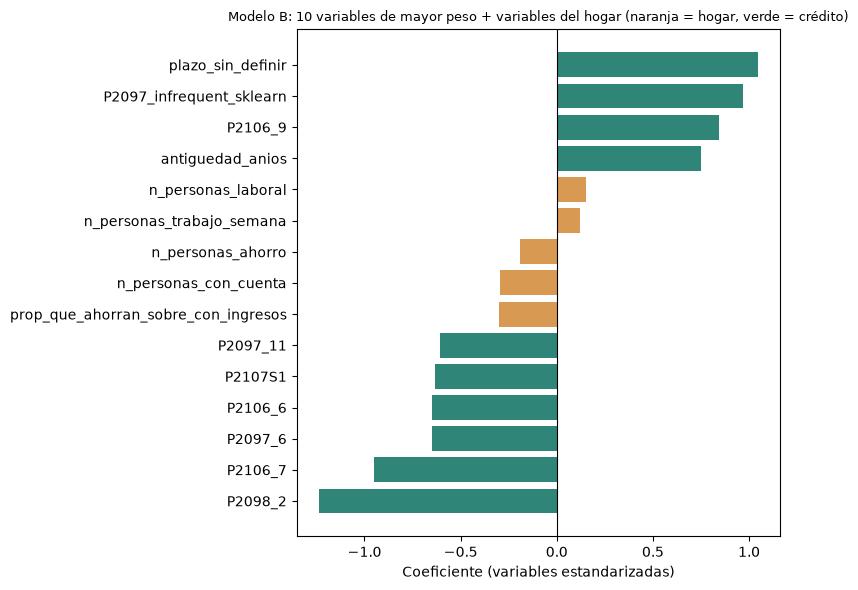

,variable,coeficiente,posicion
0,prop_que_ahorran_sobre_con_ingresos,-0.300,22
1,n_personas_con_cuenta,-0.298,23
2,n_personas_ahorro,-0.190,32
3,n_personas_laboral,0.152,34
4,n_personas_trabajo_semana,0.120,37
5,n_personas_que_ahorran,-0.090,41
6,missingindicator_prop_que_ahorran_sobre_con_in...,-0.045,43
7,n_personas_con_ingresos,-0.031,44


In [59]:
coef = res["B"]["coef"].copy()
hogar_set = set(HOGAR_NUM) | {"missingindicator_prop_que_ahorran_sobre_con_ingresos"}
coef["grupo"] = np.where(coef.variable.isin(hogar_set), "Hogar", "Crédito")
coef["posicion"] = np.arange(1, len(coef) + 1)
show = pd.concat([coef.head(10), coef[coef.grupo == "Hogar"].head(5)]).drop_duplicates("variable").sort_values("coeficiente")
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(show.variable, show.coeficiente, color=np.where(show.grupo == "Hogar", "#D89A52", "#2F8577"))
ax.axvline(0, color="k", lw=0.8); ax.set_xlabel("Coeficiente (variables estandarizadas)")
ax.set_title("Modelo B: 10 variables de mayor peso + variables del hogar (naranja = hogar, verde = crédito)", fontsize=9)
plt.tight_layout()
with mlflow.start_run(run_id=parent_run_id):
    mlflow.log_figure(fig, "coeficientes_modelo_B.png")
plt.show()
coef[coef.grupo == "Hogar"][["variable", "coeficiente", "posicion"]].round(3).reset_index(drop=True)

## 9. Observaciones sobre la v1

1. **El criterio de éxito del equipo no se alcanza.** Δ recall = +0,042 (se pedía ≥ +0,05) y Δ precisión = −0,040 (se aceptaba hasta −0,03). Ninguna de las dos condiciones se cumple, aunque por poco.
2. **El modelo B detecta algo más de atrasos, pero genera más falsas alarmas.** El recall sube de 0,642 a 0,684, la precisión baja de 0,303 a 0,263 y el F1 baja de 0,412 a 0,380 (IC 95 % de la diferencia: −0,076 a +0,009). Solo la caída de precisión es estadísticamente clara (IC de −0,075 a −0,010).
3. **Las variables del hogar tienen un peso moderado.** La proporción de personas que ahorran (coeficiente −0,33; posición 20 de 47) y el acceso a cuentas (−0,25; posición 24) se asocian con menos atrasos. Las variables laborales tienen coeficientes pequeños y de signo positivo (≈ +0,1), sin un mensaje claro, coherente con la exploración.
4. **Dominan las variables del crédito.** Las de mayor peso son el destino del crédito (la compra de vivienda reduce fuertemente la probabilidad de atraso), la ausencia de plazo definido, la antigüedad, la periodicidad de pago y la entidad acreedora.
5. **El poder predictivo es bajo a moderado.** Con una prevalencia de 16 %, un PR-AUC de ≈ 0,38 equivale a unas 2,4 veces el de un clasificador aleatorio. Con precisión de 0,26 a 0,30, de cada 10 alertas de "con retrasos" solo unas 3 son atrasos reales.

## 10. Dónde quedó registrado

Cada ejecución crea una corrida padre `v1_regresion_logistica` con tres corridas hijas (modelo A, modelo B y comparación B vs. A). En cada una de ellas MLflow guarda:

- **Parámetros:** variables usadas, hiperparámetros, umbral y datos de la partición.
- **Métricas:** validación y prueba (PR-AUC, recall, precisión, F1, ROC-AUC) y la comparación B − A.
- **Artefactos:** curva precisión-recall, matriz de confusión, coeficientes y el modelo entrenado con su firma.

In [60]:
print("Servidor MLflow:", mlflow.get_tracking_uri())
print("Run padre:", parent_run_id)

Servidor MLflow: http://32.200.160.222:8050
Run padre: f72ce50648934724b3cf4893e9ed0936
